In [4]:
# Project: Analyzing the "candidate" objects to predict the prioritization of potential candidates for further study
# by training the model on "confirmed" and "false positives".

In [5]:
## Step 01: Loading the data

In [6]:
# Load pandas and view the total no. of columns and rows
# The table has 9564 rows and 50 columns
import pandas as pd
df = pd.read_csv("cumulative.csv")
df.shape

(9564, 50)

In [7]:
# View the top-5 rows across all columns
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [8]:
# Shows total no. of values for each verdict by NASA
df["koi_disposition"].value_counts()

,count
koi_disposition,
FALSE POSITIVE,5023
CONFIRMED,2293
CANDIDATE,2248


In [9]:
# Important columns
df.columns

# The following columns were deemed relevant for training, focusing on NASA measurements: "kepoi_name", "koi_disposition", "koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq", "koi_insol", "koi_model_snr",
#"koi_impact", "koi_steff", "koi_srad"
# The remaining columns, such as kepler name, flags, etc. were left out to ensure the model doesn't cheat during the testing process.

Index(['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition',
       'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss',
       'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1',
       'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1',
       'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2',
       'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth',
       'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1',
       'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol',
       'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num',
       'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2',
       'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad',
       'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag'],
      dtype='object')

In [10]:
## Step 02: Cleaning the Data

In [11]:
# Creating a new table with the selected columns

keep = ["kepoi_name", "koi_disposition", "koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq", "koi_insol", "koi_model_snr",
"koi_impact", "koi_steff", "koi_srad"]

data = df[keep]
data.shape

(9564, 12)

In [12]:
# Counting blanks across columns

data.isnull().sum()

,0
kepoi_name,0
koi_disposition,0
koi_period,0
koi_duration,0
koi_depth,363
koi_prad,363
koi_teq,363
koi_insol,321
koi_model_snr,363
koi_impact,363


In [13]:
# Removing blank rows to avoid errors

data = data.dropna()
len(data)

9201

In [14]:
# Creating two tables for training the model and testing
# 7016 decided, 2185 potential candidates

decided = data[data["koi_disposition"] != "CANDIDATE"]
candidates = data[data["koi_disposition"] == "CANDIDATE"].copy()
print(len(decided), len(candidates))
decided["koi_disposition"].value_counts()

7016 2185


,count
koi_disposition,
FALSE POSITIVE,4724
CONFIRMED,2292


In [15]:
## Step 03: Exploring the data

In [16]:
# Details of the object sizes in Earth radii
# Note: Median size is 2.39, whereas mean is 102. This huge difference can be attributed to some outlier values.

df["koi_prad"].describe()

,koi_prad
count,9201.000000
mean,102.891778
std,3077.639126
min,0.080000
25%,1.400000
50%,2.390000
75%,14.930000
max,200346.000000


In [17]:
# Details of the object temperature
df["koi_teq"].describe()

,koi_teq
count,9201.000000
mean,1085.385828
std,856.351161
min,25.000000
25%,539.000000
50%,878.000000
75%,1379.000000
max,14667.000000


In [18]:
# Median object size categorized by the verdict.
# Preliminary observation: Median sizes for false positives was higher as compared to confirmed planets.

data.groupby("koi_disposition")["koi_prad"].median()

,koi_prad
koi_disposition,
CANDIDATE,1.78
CONFIRMED,2.17
FALSE POSITIVE,6.85


In [19]:
# Segregating objects with radius > 15 earth radii.
# Only 16 confirmed with 2122 false positives.

radius = decided[decided["koi_prad"] > 15]
radius["koi_disposition"].value_counts()

,count
koi_disposition,
FALSE POSITIVE,2122
CONFIRMED,16


In [20]:
# Median object temperature categorized by the verdict.
# Preliminary observation: Median temperature for false positives was higher as compared to confirmed planets.
decided.groupby("koi_disposition")["koi_teq"].median()

,koi_teq
koi_disposition,
CONFIRMED,781.0
FALSE POSITIVE,1095.0


In [21]:
# Segregating objects with temperature > 1379 Kelvin.
# Only 196 confirmed with 1821 false positives.

temp = decided[decided["koi_teq"] > 1379]
temp["koi_disposition"].value_counts()

,count
koi_disposition,
FALSE POSITIVE,1821
CONFIRMED,196


In [22]:
# Median object orbit period categorized by the verdict.
# Preliminary observation: Median orbit length for false positives was smaller as compared to confirmed planets.
# Stars orbiting other stars have shorter orbit lengths as compared to planets, which could explain the shorter periods.

data.groupby("koi_disposition")["koi_period"].median()

,koi_period
koi_disposition,
CANDIDATE,12.928455
CONFIRMED,11.311964
FALSE POSITIVE,5.762002


In [23]:
# Median dip in star light categorized by the verdict.
# NASA characterized certain false positives as "eclipsing binaries" or a star orbiting another star.
# This could likely be the reason why the dip in star light was much deeper, owing to the star's size, as compared to a planet.
data.groupby("koi_disposition")["koi_depth"].median()

,koi_depth
koi_disposition,
CANDIDATE,257.90
CONFIRMED,460.35
FALSE POSITIVE,548.45


In [24]:
# How much median starlight a planet receives as compared to earth
data.groupby("koi_disposition")["koi_insol"].median()

,koi_insol
koi_disposition,
CANDIDATE,84.010
CONFIRMED,87.915
FALSE POSITIVE,341.000


In [25]:
# Import seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 0, 'Planet temperature (Kelvin)')

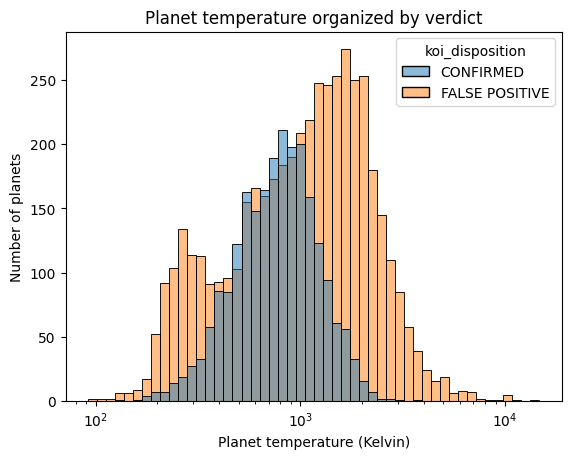

In [26]:
# Histogram depicting relationship between planet temperature and verdict
# Unusually high planet temperatures were false positives, while confirmed planets ranged from 500-1000 Kelvin.
sns.histplot(data=decided, x="koi_teq", hue="koi_disposition", log_scale=True)
plt.title("Planet temperature organized by verdict")
plt.ylabel("Number of planets")
plt.xlabel("Planet temperature (Kelvin)")

Text(0.5, 0, 'Planet size (in Earth radii)')

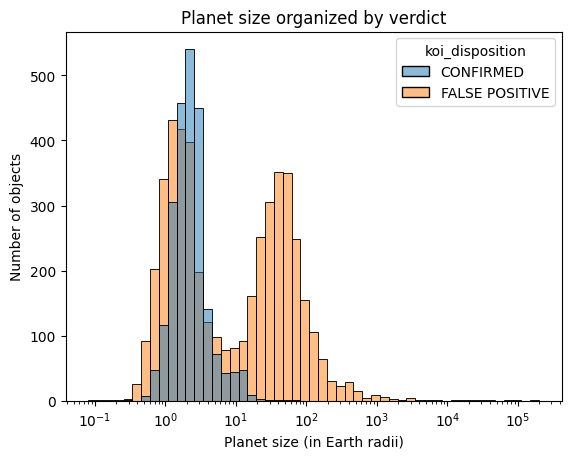

In [27]:
# Histogram depicting relationship between planet size and verdict
# Large planet sizes were characterized as false positives.
sns.histplot(data=decided, x="koi_prad", hue="koi_disposition", log_scale=True)
plt.title("Planet size organized by verdict")
plt.ylabel("Number of objects")
plt.xlabel("Planet size (in Earth radii)")

Text(0.5, 0, 'Verdict')

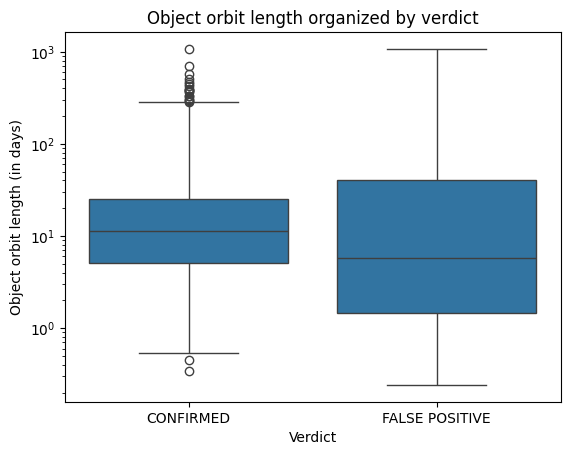

In [28]:
# Box plot depicting relationship between orbit length and verdict.
# Very short orbits were false positives, potentially indicating one star orbiting another star.
# Due to major overlap, orbit length cannot alone differentiate a confirmed planet from a false positive.
sns.boxplot(data=decided, x="koi_disposition", y="koi_period", log_scale=True)
plt.title("Object orbit length organized by verdict")
plt.ylabel("Object orbit length (in days)")
plt.xlabel("Verdict")

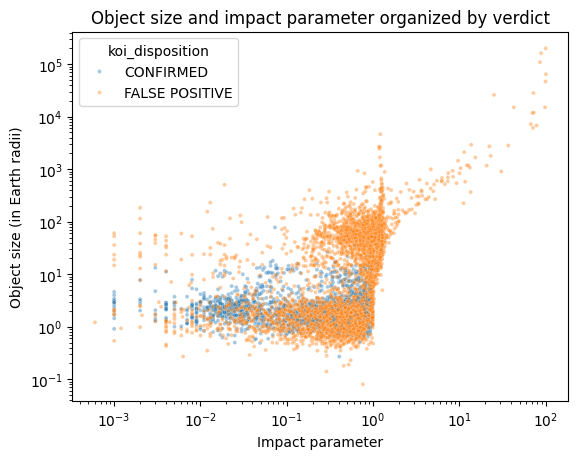

In [29]:
# Scatterplot showing a relationship between planet size and how centrally it crosses the star.
# Confirmed planets sit at the bottom-left section, with impact < 1 and size between 1 and 10 earth radii.
sns.scatterplot(data=decided, x="koi_impact", y="koi_prad", hue="koi_disposition", s=8, alpha=0.4)
plt.xscale("log")
plt.title("Object size and impact parameter organized by verdict")
plt.ylabel("Object size (in Earth radii)")
plt.xlabel("Impact parameter")
plt.yscale("log")
plt.show()

In [30]:
# Key takeaways
# False positives generally exhibited the following characteristics, among others:
# Higher temperature, bigger size, and smaller orbit period

In [31]:
## Step 04: Training the model

In [32]:
# Defining the measurement for training the model.

from sklearn.tree import DecisionTreeClassifier
features = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq",
            "koi_insol", "koi_model_snr", "koi_impact", "koi_steff", "koi_srad"]
X = decided[features]
y = decided["koi_disposition"]
X.shape

(7016, 10)

In [33]:
# From the "Decided" table, we are putting aside 20% rows for testing and 80% for training.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

5612 1404


In [54]:
# Baseline: share of the most common answer (false positives) in the test set
baseline = y_test.value_counts(normalize=True).max()
print("Baseline:", round(baseline, 2))

Baseline: 0.66


In [35]:
# Test case 1 | Depth: 3
# The gap in training and testing cases is nearly 0.02
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 0.8681397006414825 test: 0.8482905982905983


In [36]:
# Test case 2 | Depth: 6
model = DecisionTreeClassifier(max_depth=6, random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 0.9019957234497505 test: 0.8803418803418803


In [37]:
# Test case 3 | Depth: 8
model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 0.9280114041339986 test: 0.8917378917378918


In [38]:
# Test case 4 | Depth: 10
# The gap widens from 0.02 to 0.06, testing score is consistent with previous observation (nearly 0.89)
model = DecisionTreeClassifier(max_depth=10, random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 0.9517106200997861 test: 0.8917378917378918


In [39]:
# Test case 5 | Depth: 15
# The gap widens from 0.06 to 0.1
model = DecisionTreeClassifier(max_depth=15, random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 0.9855666429080542 test: 0.8874643874643875


In [40]:
# Test case 6 | Depth: No limit
# Training score reaches 1, while the testing score doesn't improve from 0.88.
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
print("train:", model.score(X_train, y_train), "test:", model.score(X_test, y_test))

train: 1.0 test: 0.8867521367521367


In [41]:
# Depth |    Training Score  |     Test Score     |
#-------------------------------------------------
#  3    | 0.8681397006414825 |  0.8482905982905983|
#  6    | 0.9019957234497505 |  0.8803418803418803|
#  8    | 0.9280114041339986 |  0.8917378917378918|
#  10   | 0.9517106200997861 |  0.8917378917378918|
#  15   | 0.9855666429080542 |  0.8874643874643875|
#  Null |         1.0        |  0.8867521367521367|

# The wide gap between training and testing scores in the last test case indicates "overfitting": a case where the model asks unlimited questions to categorize every signal as false positive or confirmed.
# At a depth of 8-10, the test score remains the same, while the gap between training and test scores further increases.


In [55]:
# Relative improvement from the baseline

model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X_train, y_train)
test_score = model.score(X_test, y_test)
print("train:", model.score(X_train, y_train), "test:", test_score)
print("Baseline:", round(baseline, 2))

relative = (test_score - baseline) / baseline * 100
points = (test_score - baseline) * 100
print("Relative improvement:", round(relative, 1), "%")
print("Improvement:", round(points, 1), "percentage points")

train: 0.9280114041339986 test: 0.8917378917378918
Baseline: 0.66
Relative improvement: 34.2 %
Improvement: 22.7 percentage points


In [43]:
# Detailed decision matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
pred = model.predict(X_test)
confusion_matrix(y_test, pred)

# Out of the total 471 confirmed planets, the model correctly identified 426.
# Out of the total 933 false positives, the model correctly identified 826.


array([[426,  45],
       [107, 826]])

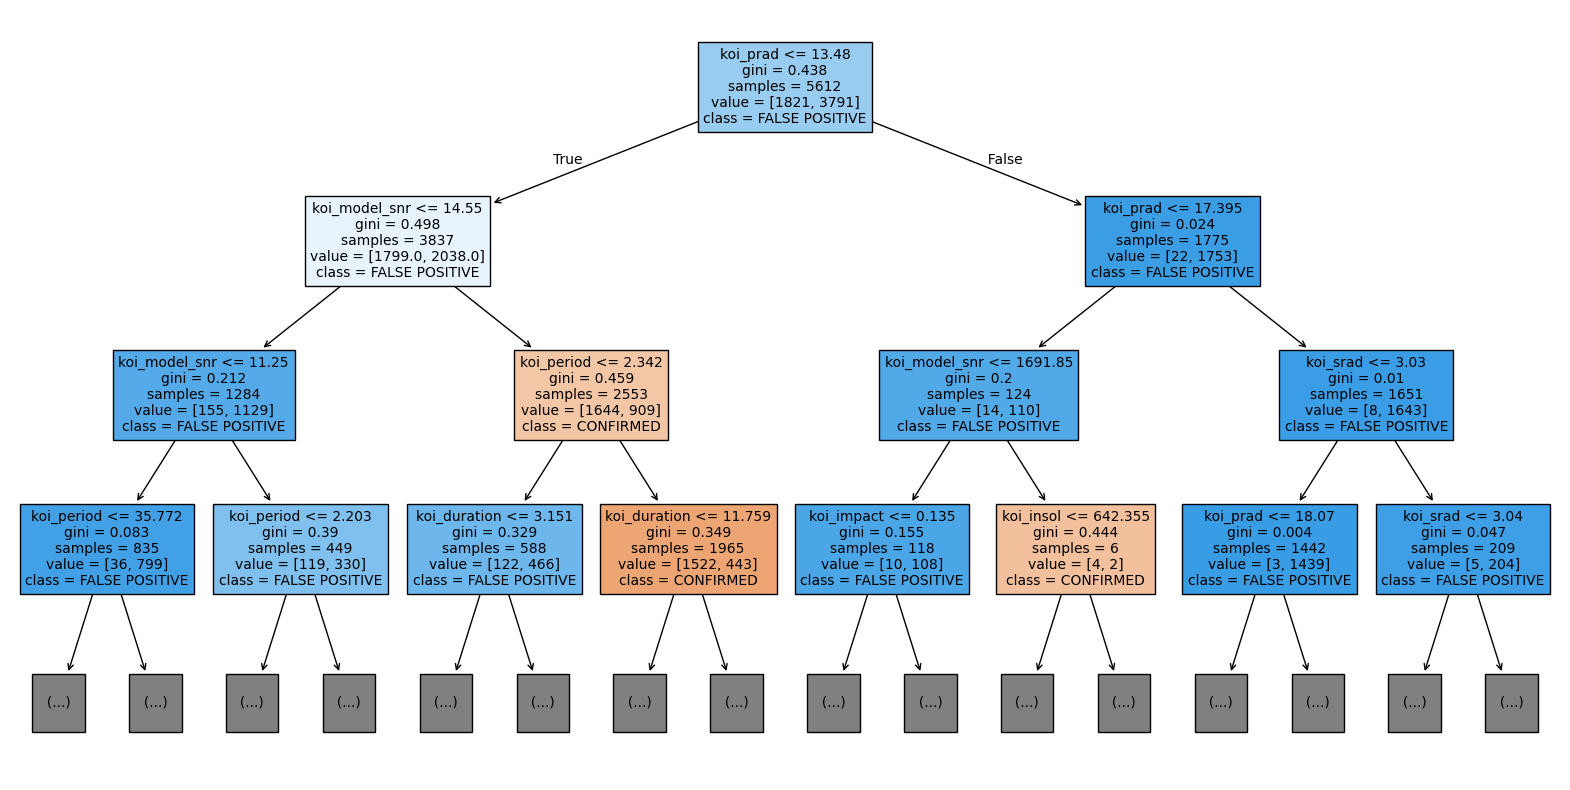

In [44]:
# Visual representation of the tree

from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))
plot_tree(model, feature_names=features, class_names=model.classes_, filled=True, max_depth=3, fontsize=10)
plt.show()

In [45]:
## Step 05: Testing on candidates

In [46]:
# Defining the measurement for testing the model.

from sklearn.tree import DecisionTreeClassifier
features = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq",
            "koi_insol", "koi_model_snr", "koi_impact", "koi_steff", "koi_srad"]
X_cand = candidates[features]
X_cand.shape

(2185, 10)

In [56]:
# Predicting the candidates

print(candidates["prediction"].value_counts())

prediction
FALSE POSITIVE    1279
CONFIRMED          906
Name: count, dtype: int64


In [48]:
# List of potential planets

candidates["sureness"] = model.predict_proba(X_cand)[:, 0]
candidates.sort_values("sureness", ascending=False).head(10)

,kepoi_name,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_impact,koi_steff,koi_srad,prediction,sureness
9136,K02807.01,CANDIDATE,3.375717,1.5436,175.7,2.34,1472.0,1111.66,20.2,0.9820,6310.0,1.282,CONFIRMED,1.0
4484,K04777.01,CANDIDATE,0.824000,0.8550,183.1,0.42,746.0,73.09,12.3,0.7697,3396.0,0.280,CONFIRMED,1.0
4631,K04810.01,CANDIDATE,115.238544,7.6530,516.7,3.17,372.0,4.52,10.6,0.9650,5589.0,1.037,CONFIRMED,1.0
3939,K04447.01,CANDIDATE,2.186602,1.5850,122.3,0.98,1099.0,345.07,14.2,0.8280,4904.0,0.772,CONFIRMED,1.0
8853,K06526.01,CANDIDATE,486.778320,15.2900,370.8,9.30,409.0,6.60,10.4,0.1737,5039.0,4.950,CONFIRMED,1.0
4224,K04715.01,CANDIDATE,53.285584,6.4920,158.6,1.44,537.0,19.63,11.0,0.7540,6015.0,1.057,CONFIRMED,1.0
4233,K04577.01,CANDIDATE,105.997107,3.7510,430.8,1.83,373.0,4.59,10.9,0.6670,6068.0,0.831,CONFIRMED,1.0
3919,K04235.01,CANDIDATE,66.643456,2.3850,277.3,2.99,476.0,12.17,14.8,0.9850,5751.0,1.164,CONFIRMED,1.0
5719,K03943.01,CANDIDATE,38.576348,19.8610,282.1,2.05,619.0,34.77,76.3,0.0150,6167.0,1.221,CONFIRMED,1.0
670,K01239.01,CANDIDATE,0.783276,1.6735,264.7,1.98,2149.0,5056.88,46.9,0.0410,5640.0,1.233,CONFIRMED,1.0


In [49]:
very_likely = candidates[candidates["sureness"] >= 0.8]
print(len(very_likely))

316


In [50]:
## Step 06: Checking against latest data

In [51]:
# Reading the file and renaming column

nasa = pd.read_csv("nasa_now.csv", comment="#")
nasa = nasa[["kepoi_name", "koi_disposition"]]
nasa = nasa.rename(columns={"koi_disposition": "nasa_now"})

In [52]:
# Merging two tables

check = candidates.merge(nasa, on="kepoi_name")

In [53]:
# Checking the model's prediction against recent data from NASA

print(check["nasa_now"].value_counts())
pd.crosstab(check["prediction"], check["nasa_now"])

nasa_now
CANDIDATE         1598
CONFIRMED          442
FALSE POSITIVE     145
Name: count, dtype: int64


nasa_now,CANDIDATE,CONFIRMED,FALSE POSITIVE
prediction,,,
CONFIRMED,500,377,29
FALSE POSITIVE,1098,65,116


**Findings:**

*   According to NASA, an eclipsing binary is two stars orbiting each other, where one passes in front of the other as seen from Earth. This pattern could potentially explain the higher median for the false positive readings for object temperature and size, as well as shorter orbital periods.

*   The scatter plot demonstrated that confirmed planets sit at the bottom-left section, with impact < 1 and size between 1 and 10 earth radii. On the other hand, false positives had large sizes which is not typical of planets and had grazing impacts (around 1 or above).

*   The original baseline from the dataset (66%) improved by nearly 23 percentage points when the "max depth" was chosen as 8 for the decision tree.

*   The model predicted 906 confirmed planets, and 316 had a planet share of 0.8 or higher.

*   When the depth of the decision tree was increased, its training and test scores showed a wider gap. At a depth of 8-10, the training score rose sharply while the test score remained stagnant at 0.89.

*   From the original candidates, NASA has confirmed 442 as real planets, of my 2,185 cleaned candidates, through additional exploration and data.

*   Using this model, 377 out of 406, of the flagged candidates NASA has since resolved, were real planets (93%). When it predicted ‘false positive’, it was right 64% of the time (116 of 181).

*   For candidates NASA has since resolved, always guessing ‘planet’ would be right 75% of the time (442 real planets ÷ 587 resolved). The tree scores 84% ((377 + 116) ÷ 587), which is 9 percentage points higher.

**Limitations:**

*   The data is taken from 2017 Kepler data snapshot so the data might be outdated.

*   Certain rows with missing values were removed, leaving 2185 candidates, before the analysis so they are not accounted for in the prediction.

*   Planets and false positives can have large overlaps if they are similar in sizes, which can make it challenging for the model to predict.

*   NASA further used additional data and research that this model does not have.


**Next steps:**

*   Include more test cases with different data columns, such as planet positioning, error rate, etc. to test if the test accuracy varies.

*   Use random forest to see if it gives a different prediction.

**Sources:**

*  NASA Kepler KOI table (2017 snapshot, from Kaggle): https://www.kaggle.com/datasets/nasa/kepler-exoplanet-search-results
*  NASA’s current KOI table: https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=cumulative

**Files:**

Kepler_Analysis.ipynb. To run it, upload cumulative.csv and nasa_now.csv.

**Acknowledgements**

I learned Python, pandas and scikit-learn for this project with guidance from Claude (Anthropic's AI assistant), which acted as a tutor and explained concepts, reviewed my code, answered questions, and helped me interpret the results. I wrote the code and made certain modelling decisions, such as features to train the model on, tree depth, validation against NASA’s current data, and wrote the findings.
